# Instagram Analytics: Data Validation and Exploratory Data Analysis

**Project:** SUGAR Cosmetics Instagram Performance  
**Author:** Kartikey Singh  
**Role:** Data Analyst  
**Analysis type:** Data-quality audit and descriptive exploratory data analysis

---

## Executive Summary

### Business Objective

Assess the quality and structure of the supplied Instagram performance dataset, then explore descriptive patterns across post formats, campaign types, engagement sources, audience-emotion labels, dates, and hashtags. The goal is to identify reliable performance signals and define practical follow-up analyses—not to claim causal impact.

### Why This Analysis Matters

A consistent validation and exploratory analysis workflow helps stakeholders distinguish data-quality issues from potentially useful performance patterns. It also makes metric definitions, assumptions, and limitations transparent before results are used in content or campaign decisions.

### Key Findings at a Glance

The notebook calculates dataset-specific findings from the loaded source. Run all cells from top to bottom before completing this summary. Review the overall KPIs, category comparisons, monthly trends, and hashtag results; do not declare a winning format or campaign until the calculated results and supporting sample sizes have been checked.

### Interpretation Guardrails

- **Descriptive, not causal:** observed differences do not prove that a format, campaign, or hashtag caused better performance.
- **Reach is not unique reach:** summing post-level reach may count overlapping audiences more than once.
- **No silent data removal:** source records are retained; potential anomalies are flagged for review rather than automatically deleted or imputed.
- **Conversion proxies are not attribution:** aggregate visit-to-follow ratios are not person-level conversion measures.
- **Source provenance is unverified:** data ownership, collection method, and row-level grain have not been independently established.

## Notebook Roadmap

1. Environment and configuration
2. Data loading and schema validation
3. Data-quality assessment
4. Data cleaning and feature engineering
5. Overall performance and univariate analysis
6. Category coverage and performance
7. Time-series exploration
8. Hashtag exploration
9. Findings, limitations, and audit exports
10. Conclusion and recommendations

### How to Run This Notebook

Execute the notebook from top to bottom in a fresh kernel. The expected project structure includes a `data/` directory containing `sugar_cosmetics_instagram_data.csv`; an Excel workbook is used as a fallback when available. Audit outputs are written to `reports/`.


## 1. Environment and Configuration

Import dependencies in one place, set reproducibility defaults, and resolve project paths relative to the project directory rather than a machine-specific absolute path.

Expected layout:
```text
project/
├── data/
│   ├── sugar_cosmetics_instagram_data.csv
│   └── sugar_cosmetics_instagram_data.xlsx  # optional fallback
├── reports/                                 # generated outputs
└── notebooks/
    └── 01_data_validation_and_eda.ipynb
```

The setup cell searches the current directory and its parent for `data/`. Update `PROJECT_ROOT` there if your project uses a different layout.


In [1]:
from pathlib import Path
import hashlib
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 42
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
REPORT_DIR = PROJECT_ROOT / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "sugar_cosmetics_instagram_data.csv"
EXCEL_PATH = DATA_DIR / "sugar_cosmetics_instagram_data.xlsx"
print(f"Project root: {PROJECT_ROOT}")
print(f"CSV available: {CSV_PATH.exists()} | workbook fallback available: {EXCEL_PATH.exists()}")


Project root: d:\sugar_cosmetics_instagram_analytics
CSV available: True | workbook fallback available: True


### Load the source dataset

Select the CSV when available; otherwise use the Excel fallback. Source path and fingerprint are captured for traceability.


In [2]:
if CSV_PATH.exists():
    raw = pd.read_csv(CSV_PATH)
    source_path = CSV_PATH
elif EXCEL_PATH.exists():
    raw = pd.read_excel(EXCEL_PATH)
    source_path = EXCEL_PATH
else:
    raise FileNotFoundError("Expected the project CSV or workbook in data/.")

source_sha256 = hashlib.sha256(source_path.read_bytes()).hexdigest()
source_shape = raw.shape
original_columns = raw.columns.astype(str).tolist()

def standardize_column(name):
    name = str(name).strip().lower()
    return re.sub(r"[^a-z0-9]+", "_", name).strip("_")

raw.columns = [standardize_column(c) for c in raw.columns]
source_record = pd.DataFrame([
    {"Item": "Selected source", "Value": source_path.relative_to(PROJECT_ROOT).as_posix()},
    {"Item": "Source file SHA-256", "Value": source_sha256},
    {"Item": "Source dimensions", "Value": f"{source_shape[0]:,} rows × {source_shape[1]} columns"},
    {"Item": "Original column names", "Value": ", ".join(original_columns)},
])


### Record the selected source

This output documents which input file was selected and its basic ingestion metadata.


In [3]:
display(source_record)

,Item,Value
0,Selected source,data/sugar_cosmetics_instagram_data.csv
1,Source file SHA-256,b64c154cfb7594fcc74119722350d849957ca44cd0a4f7...
2,Source dimensions,"50,000 rows × 14 columns"
3,Original column names,"post_date, post_type, campaign_type, hashtags,..."


## 2. Data Loading and Schema Validation

Standardize column names and parse fields needed for analysis, then compare the resulting schema with expected fields.

**Validation questions**

- Did the expected source load successfully?

- Are required columns present?

- What are the dataset dimensions, data types, missingness, and sample records?

The source is inspected before derived metrics are added.


### Inspect sample records

Review representative rows to confirm that values look plausible before interpreting validation results.


In [4]:
display(raw.head(10))

,post_date,post_type,campaign_type,hashtags,audience_emotion,engagement_source,impressions,reach,likes,comments,shares,saves,profile_visits,follows
0,2024-12-23,Story,Giveaway,"#SugarCosmetics, #MakeupGoals, #BoldLooks",Curious,Collab,16795,15665,3076,430,73,99,193,86
1,2024-06-01,Image,Tutorial,"#BoldLooks, #MakeupGoals, #VeganBeauty",Confident,Influencer,45131,29335,5285,308,396,502,294,146
2,2024-04-28,Reel,Festive Offer,#VeganBeauty,Confident,Collab,18568,13118,2032,233,73,140,204,44
3,2025-02-01,Reel,Product Launch,"#CrueltyFree, #VeganBeauty, #SugarCosmetics",Happy,Collab,1189,751,130,13,12,7,33,12
4,2024-08-04,Story,Tutorial,"#SugarCosmetics, #VeganBeauty",Curious,Organic,15502,9373,2234,300,99,47,180,35
5,2024-07-23,Image,Product Launch,#SugarCosmetics,Happy,Paid,24483,15735,2345,129,215,95,574,128
6,2024-07-14,Reel,Product Launch,"#CrueltyFree, #SugarCosmetics",Happy,Influencer,12653,8512,1392,76,119,77,219,103
7,2024-06-12,Video,Festive Offer,#CrueltyFree,Excited,Influencer,33606,31006,2099,166,29,96,792,165
8,2025-01-30,Video,Festive Offer,"#SugarCosmetics, #VeganBeauty, #MakeupGoals",Inspired,Collab,10268,8269,2009,283,69,87,137,14
9,2024-05-29,Image,Festive Offer,"#MakeupGoals, #CrueltyFree",Happy,Organic,3568,3105,278,14,23,21,121,49


### Validate required fields and normalize the schema

Check required columns and prepare standardized fields for downstream analysis.


In [5]:
required_columns = {
    "post_date", "post_type", "campaign_type", "hashtags", "audience_emotion",
    "engagement_source", "impressions", "reach", "likes", "comments",
    "shares", "saves", "profile_visits", "follows",
}
missing_required = sorted(required_columns - set(raw.columns))
unexpected_columns = sorted(set(raw.columns) - required_columns)
if missing_required:
    raise ValueError(f"Required columns missing from source: {missing_required}")

df = raw.copy()
df["post_date"] = pd.to_datetime(df["post_date"], errors="coerce")
numeric_columns = ["impressions", "reach", "likes", "comments", "shares", "saves", "profile_visits", "follows"]
for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")
categorical_columns = ["post_type", "campaign_type", "hashtags", "audience_emotion", "engagement_source"]
for column in categorical_columns:
    df[column] = df[column].astype("string").str.strip().replace("", pd.NA)


### Review schema and missingness

The schema table reports parsed types, missing counts and percentages, and distinct-value counts.


In [6]:
schema = pd.DataFrame({
    "Column": df.columns,
    "Type after parsing": [str(df[c].dtype) for c in df.columns],
    "Missing": [int(df[c].isna().sum()) for c in df.columns],
    "Missing (%)": [float(df[c].isna().mean() * 100) for c in df.columns],
    "Distinct non-missing": [int(df[c].nunique(dropna=True)) for c in df.columns],
})
print("Unexpected columns:", unexpected_columns or "None")
display(schema)


Unexpected columns: None


,Column,Type after parsing,Missing,Missing (%),Distinct non-missing
0,post_date,datetime64[ns],0,0.0,366
1,post_type,string,0,0.0,4
2,campaign_type,string,0,0.0,5
3,hashtags,string,0,0.0,85
4,audience_emotion,string,0,0.0,5
5,engagement_source,string,0,0.0,4
6,impressions,int64,0,0.0,31462
7,reach,int64,0,0.0,29010
8,likes,int64,0,0.0,8604
9,comments,int64,0,0.0,1677


## 3. Data-Quality Assessment

Run transparent checks for missing values, duplicate rows, invalid values, and other conditions that may affect interpretation.

**How to read the checks:** counts are diagnostics, not automatic proof that a record is incorrect. Review non-zero counts against source records and data-owner definitions before changing values.


### Run quality checks

Each check returns a count, review priority, and interpretation. These are investigation prompts, not automatic corrections.


In [7]:
quality_checks = []
def add_check(check, count, severity, interpretation):
    quality_checks.append({"Check": check, "Count": int(count), "Review priority": severity, "Interpretation": interpretation})

add_check("Missing cells", df.isna().sum().sum(), "Review", "Inspect affected fields; no imputation is applied here.")
add_check("Exact duplicate rows", df.duplicated().sum(), "Review", "Without a post ID, exact duplicates do not establish duplicate posts.")
add_check("Invalid or missing dates", df["post_date"].isna().sum(), "High", "Rows without valid dates are unavailable for temporal summaries.")
for column in numeric_columns:
    add_check(f"Missing or non-numeric: {column}", df[column].isna().sum(), "Review", "Compare with source definitions before excluding or imputing.")
    add_check(f"Negative values: {column}", (df[column] < 0).sum(), "High", "Review source values; do not silently clamp counts.")
add_check("Impressions below reach", (df["impressions"] < df["reach"]).sum(), "Review", "Definitions can vary; inspect against source documentation.")
eligible_engagements = df[["likes", "comments", "shares", "saves"]].sum(axis=1, min_count=4)
add_check("Engagement actions above reach", (eligible_engagements > df["reach"]).sum(), "Review", "Repeated actions or metric definitions may explain these records.")
add_check("Zero reach", (df["reach"] == 0).sum(), "Review", "Engagement rate is undefined when reach is zero.")
add_check("Zero profile visits", (df["profile_visits"] == 0).sum(), "Info", "Follow-per-visit ratio is undefined when visits are zero.")
quality_df = pd.DataFrame(quality_checks)


### Quality-check results

Inspect the diagnostic table before continuing.


In [8]:
display(quality_df)

,Check,Count,Review priority,Interpretation
0,Missing cells,0,Review,Inspect affected fields; no imputation is appl...
1,Exact duplicate rows,0,Review,"Without a post ID, exact duplicates do not est..."
2,Invalid or missing dates,0,High,Rows without valid dates are unavailable for t...
3,Missing or non-numeric: impressions,0,Review,Compare with source definitions before excludi...
4,Negative values: impressions,0,High,Review source values; do not silently clamp co...
5,Missing or non-numeric: reach,0,Review,Compare with source definitions before excludi...
6,Negative values: reach,0,High,Review source values; do not silently clamp co...
7,Missing or non-numeric: likes,0,Review,Compare with source definitions before excludi...
8,Negative values: likes,0,High,Review source values; do not silently clamp co...
9,Missing or non-numeric: comments,0,Review,Compare with source definitions before excludi...


### Overall data-quality snapshot

Summarize dataset dimensions and main quality indicators.


In [9]:
quality_overview = pd.DataFrame([{
    "Rows": len(df),
    "Source columns": len(raw.columns),
    "Missing cells": int(df.isna().sum().sum()),
    "Exact duplicate rows": int(df.duplicated().sum()),
    "Invalid dates": int(df["post_date"].isna().sum()),
    "First valid date": df["post_date"].min().date() if df["post_date"].notna().any() else None,
    "Last valid date": df["post_date"].max().date() if df["post_date"].notna().any() else None,
}])
display(quality_overview)


,Rows,Source columns,Missing cells,Exact duplicate rows,Invalid dates,First valid date,Last valid date
0,50000,14,0,0,0,2024-04-19,2025-04-19


## 4. Data Cleaning and Feature Engineering

Create an analysis copy and apply explicit, logged transformations. Source rows are retained; the notebook does not silently drop records, impute values, or overwrite outliers.

Derived measures include:

- **Total engagements:** likes + comments + shares + saves, where all components are available.

- **Engagement rate:** total engagements divided by reach when reach is positive.

- **Visit/follow ratios:** aggregate descriptive proxies where source fields permit them.

Confirm metric definitions with the data owner before external reporting.


### Create analysis features and log transformations

Derived metrics are added to a copy of the standardized dataset; missing components are not silently treated as zero.


In [10]:
clean = df.copy()
clean["total_engagements"] = clean[["likes", "comments", "shares", "saves"]].sum(axis=1, min_count=4)
clean["engagement_rate"] = clean["total_engagements"] / clean["reach"].where(clean["reach"] > 0)
clean["profile_visit_rate_proxy"] = clean["profile_visits"] / clean["reach"].where(clean["reach"] > 0)
clean["follow_per_visit_rate_proxy"] = clean["follows"] / clean["profile_visits"].where(clean["profile_visits"] > 0)
clean["follow_per_reach_rate_proxy"] = clean["follows"] / clean["reach"].where(clean["reach"] > 0)
clean["month"] = clean["post_date"].dt.to_period("M").astype("string")
clean["weekday"] = clean["post_date"].dt.day_name().astype("string")
cleaning_log = pd.DataFrame([
    {"Step": "Standardize column names", "Rows affected": len(clean), "Action": "Normalize names to lowercase snake_case."},
    {"Step": "Parse date and numeric fields", "Rows affected": len(clean), "Action": "Unparseable values become missing and are counted in validation."},
    {"Step": "Create engagement and rate fields", "Rows affected": len(clean), "Action": "Keep source columns; zero denominator produces missing rate."},
    {"Step": "Drop or impute source rows", "Rows affected": 0, "Action": "No automatic row exclusion or imputation."},
])


### Cleaning and feature-engineering log

Review each transformation and its rationale.


In [11]:
display(cleaning_log)

,Step,Rows affected,Action
0,Standardize column names,50000,Normalize names to lowercase snake_case.
1,Parse date and numeric fields,50000,Unparseable values become missing and are coun...
2,Create engagement and rate fields,50000,Keep source columns; zero denominator produces...
3,Drop or impute source rows,0,No automatic row exclusion or imputation.


## 5. Overall Performance and Univariate Analysis

Review overall totals and distributions for reach, impressions, engagement counts, engagement rate, and related numeric measures. Summary statistics and IQR-based screening help identify skew and values that merit investigation.

**Interpretation note:** an outlier flag is a review signal, not a deletion rule. Extreme values can reflect viral posts, large audiences, or data issues.


### Calculate overall KPIs

Compute totals and aggregate rates using explicit denominator rules; non-positive reach is excluded from rate denominators.


In [12]:
valid_reach = clean["reach"].where(clean["reach"] > 0)
total_engagements = clean["total_engagements"].sum(min_count=1)
total_reach = clean["reach"].sum(min_count=1)
total_visits = clean["profile_visits"].sum(min_count=1)
total_follows = clean["follows"].sum(min_count=1)
overall_kpis = pd.DataFrame([
    {"Measure": "Rows analyzed", "Value": f"{len(clean):,}", "Definition / caveat": "One row is not verified as one unique post."},
    {"Measure": "Total engagements", "Value": f"{total_engagements:,.0f}", "Definition / caveat": "Likes + comments + shares + saves."},
    {"Measure": "Summed post-level reach", "Value": f"{total_reach:,.0f}", "Definition / caveat": "Not deduplicated unique people."},
    {"Measure": "Weighted engagement rate", "Value": f"{total_engagements / total_reach:.2%}", "Definition / caveat": "Total engagements ÷ summed positive reach."},
    {"Measure": "Profile visits / summed reach", "Value": f"{total_visits / total_reach:.2%}", "Definition / caveat": "Aggregate proxy; no person-level linkage."},
    {"Measure": "Follows / profile visits", "Value": f"{total_follows / total_visits:.2%}", "Definition / caveat": "Aggregate proxy; not attributed conversion."},
])
display(overall_kpis)


,Measure,Value,Definition / caveat
0,Rows analyzed,"50,000",One row is not verified as one unique post.
1,Total engagements,"183,164,417",Likes + comments + shares + saves.
2,Summed post-level reach,"987,423,288",Not deduplicated unique people.
3,Weighted engagement rate,18.55%,Total engagements ÷ summed positive reach.
4,Profile visits / summed reach,3.00%,Aggregate proxy; no person-level linkage.
5,Follows / profile visits,29.92%,Aggregate proxy; not attributed conversion.


### Numeric summary statistics

Percentiles help show skew and spread beyond the mean and standard deviation.


In [13]:
distribution_summary = clean[numeric_columns + ["total_engagements", "engagement_rate"]].describe(
    percentiles=[.01, .05, .25, .50, .75, .95, .99]
).T.reset_index(names="Metric")
display(distribution_summary)


,Metric,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,impressions,50000.0,25520.915000,14118.653466,1002.000000,1527.990000,3478.950000,13243.000000,25541.000000,37758.250000,47529.150000,49507.000000,49999.000000
1,reach,50000.0,19748.465760,11311.962456,616.000000,1162.990000,2651.900000,10157.750000,19393.500000,28763.250000,38659.000000,43523.010000,47329.000000
2,likes,50000.0,2954.565580,2144.918922,40.000000,138.000000,330.000000,1256.000000,2466.000000,4255.000000,7184.000000,9024.000000,11392.000000
3,comments,50000.0,369.187220,311.676485,2.000000,14.000000,35.000000,135.000000,282.000000,516.000000,1005.000000,1384.000000,2205.000000
4,shares,50000.0,162.306760,151.722516,0.000000,4.000000,13.000000,50.000000,114.000000,228.000000,477.000000,677.000000,1072.000000
5,saves,50000.0,177.228780,154.949330,1.000000,6.000000,16.000000,62.000000,132.000000,246.000000,496.000000,702.000000,1057.000000
6,profile_visits,50000.0,592.695960,428.221806,7.000000,28.000000,65.000000,252.000000,497.000000,851.000000,1435.000000,1796.010000,2264.000000
7,follows,50000.0,177.334200,154.550825,0.000000,6.000000,16.000000,63.000000,133.000000,245.000000,496.000000,695.000000,1114.000000
8,total_engagements,50000.0,3663.288340,2669.353466,50.000000,170.000000,408.950000,1552.000000,3058.500000,5271.000000,8912.050000,11236.010000,14980.000000
9,engagement_rate,50000.0,0.185352,0.071957,0.055931,0.063571,0.073941,0.123199,0.184946,0.246417,0.298122,0.317028,0.340991


### Screen for potential outliers

The IQR rule identifies values outside conventional fences. Flags are retained for review and do not remove records.


In [14]:
outlier_rows = []
for column in numeric_columns + ["total_engagements", "engagement_rate"]:
    values = clean[column].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (clean[column] < lower) | (clean[column] > upper)
    outlier_rows.append({"Metric": column, "Q1": q1, "Q3": q3, "IQR lower fence": lower,
                         "IQR upper fence": upper, "Flagged rows": int(flagged.sum()),
                         "Flagged (%)": float(flagged.mean() * 100)})
outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)


,Metric,Q1,Q3,IQR lower fence,IQR upper fence,Flagged rows,Flagged (%)
0,impressions,13243.000000,37758.250000,-23529.875000,74531.125000,0,0.000
1,reach,10157.750000,28763.250000,-17750.500000,56671.500000,0,0.000
2,likes,1256.000000,4255.000000,-3242.500000,8753.500000,674,1.348
3,comments,135.000000,516.000000,-436.500000,1087.500000,1836,3.672
4,shares,50.000000,228.000000,-217.000000,495.000000,2180,4.360
5,saves,62.000000,246.000000,-214.000000,522.000000,2101,4.202
6,profile_visits,252.000000,851.000000,-646.500000,1749.500000,635,1.270
7,follows,63.000000,245.000000,-210.000000,518.000000,2152,4.304
8,total_engagements,1552.000000,5271.000000,-4026.500000,10849.500000,689,1.378
9,engagement_rate,0.123199,0.246417,-0.061628,0.431244,0,0.000


### Reach and impressions distributions

These counts are strongly skewed, so the chart uses `log1p` on the horizontal axis. The underlying values are not transformed in the analysis tables.


### Plot reach and impressions

The horizontal scale uses `log1p` to make skewed distributions easier to inspect; underlying values remain unchanged.


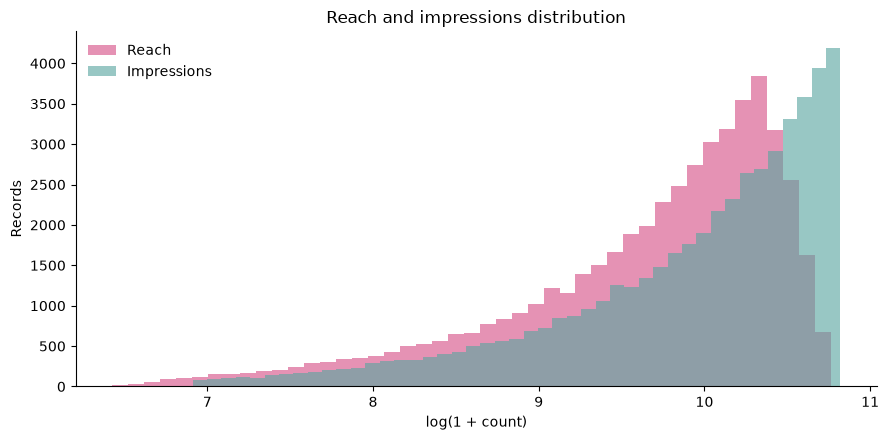

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for metric, color in [("reach", "#d64f87"), ("impressions", "#59a6a0")]:
    ax.hist(np.log1p(clean[metric].dropna()), bins=45, alpha=.62, label=metric.title(), color=color)
ax.set(title="Reach and impressions distribution", xlabel="log(1 + count)", ylabel="Records")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


### Engagement rate distribution

Rates are shown as percentage points. Extreme values remain in the plot and are described in the outlier table.


### Plot engagement-rate distribution

Rates are displayed in percentage points for readability.


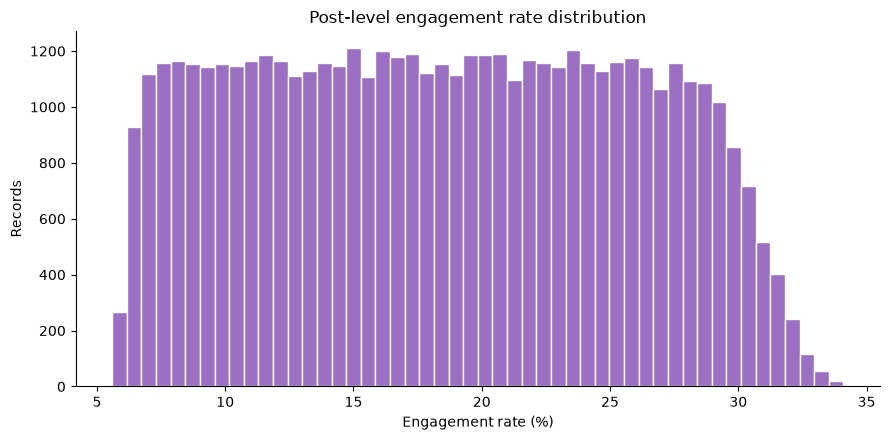

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
rate_pct = clean["engagement_rate"].dropna() * 100
ax.hist(rate_pct, bins=50, color="#9b6fc1", edgecolor="white")
ax.set(title="Post-level engagement rate distribution", xlabel="Engagement rate (%)", ylabel="Records")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


## 6. Category Coverage and Performance

Compare the volume and descriptive performance of post types, campaign types, engagement sources, and audience-emotion labels. Weighted engagement rate uses aggregated engagements and reach; mean post-level rate answers a different question.

**Decision guardrail:** check record count and denominator alongside every rate. These summaries alone do not establish statistical significance or causality.


### Define reusable grouped metrics

Use a shared aggregation function so category comparisons apply consistent metric definitions.


In [17]:
def grouped_metrics(data, group_col):
    result = data.groupby(group_col, dropna=False).agg(
        records=(group_col, "size"), reach=("reach", "sum"),
        engagements=("total_engagements", "sum"), mean_post_rate=("engagement_rate", "mean"),
    ).reset_index()
    result["weighted_rate"] = result["engagements"] / result["reach"].where(result["reach"] > 0)
    result["record_share_pct"] = result["records"] / len(data) * 100
    return result

post_type_summary = grouped_metrics(clean, "post_type").sort_values("weighted_rate", ascending=False)
campaign_summary = grouped_metrics(clean, "campaign_type").sort_values("weighted_rate", ascending=False)


### Measure category coverage

Compare record counts across major categorical fields, including missing labels.


In [18]:
category_counts = pd.concat([
    clean["post_type"].value_counts(dropna=False).rename_axis("Category").reset_index(name="Records").assign(Field="Post type"),
    clean["campaign_type"].value_counts(dropna=False).rename_axis("Category").reset_index(name="Records").assign(Field="Campaign type"),
], ignore_index=True)[["Field", "Category", "Records"]]
display(category_counts)


,Field,Category,Records
0,Post type,Reel,12599
1,Post type,Story,12517
2,Post type,Video,12485
3,Post type,Image,12399
4,Campaign type,Tutorial,10186
5,Campaign type,Giveaway,9998
6,Campaign type,Festive Offer,9990
7,Campaign type,Product Launch,9923
8,Campaign type,Influencer Collab,9903


### Visualize post-type coverage

The chart highlights how records are distributed across post types.


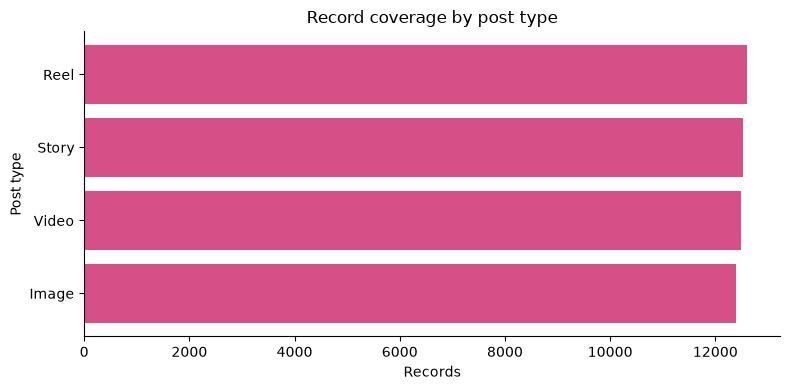

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
type_counts = clean["post_type"].value_counts(dropna=False).sort_values()
ax.barh(type_counts.index.fillna("Missing").astype(str), type_counts.values, color="#d64f87")
ax.set(title="Record coverage by post type", xlabel="Records", ylabel="Post type")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


### Post-type performance table

Read weighted rate alongside record count and summed reach.


In [20]:
display(post_type_summary.rename(columns={"post_type": "Post type", "records": "Records", "reach": "Summed reach", "engagements": "Engagements", "mean_post_rate": "Mean post rate", "weighted_rate": "Weighted rate", "record_share_pct": "Record share (%)"}))

,Post type,Records,Summed reach,Engagements,Mean post rate,Weighted rate,Record share (%)
2,Story,12517,247114187,46026060,0.185977,0.186254,25.034
1,Reel,12599,248574276,46225786,0.186085,0.185964,25.198
3,Video,12485,245445633,45557380,0.185063,0.185611,24.970
0,Image,12399,246289192,45355191,0.184266,0.184154,24.798


### Compare weighted engagement by post type

This plot is descriptive; investigate sample size and uncertainty before treating small differences as meaningful.


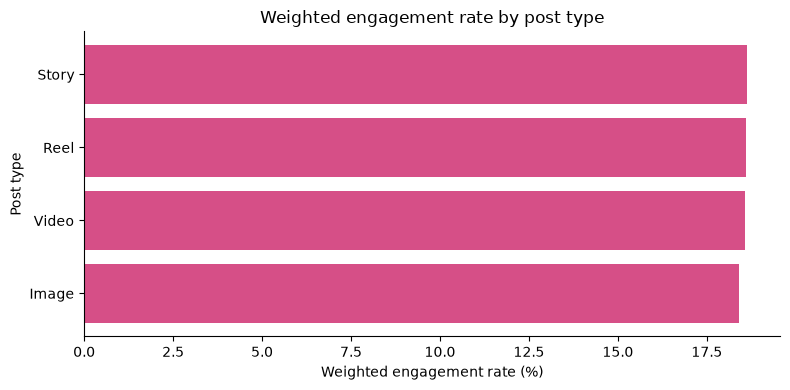

In [21]:
fig, ax = plt.subplots(figsize=(8, 4))
plot_data = post_type_summary.sort_values("weighted_rate")
ax.barh(plot_data["post_type"].astype(str), plot_data["weighted_rate"] * 100, color="#d64f87")
ax.set(title="Weighted engagement rate by post type", xlabel="Weighted engagement rate (%)", ylabel="Post type")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


### Campaign performance table

Compare campaign groups with both rate and volume context.


In [22]:
display(campaign_summary.rename(columns={"campaign_type": "Campaign", "records": "Records", "reach": "Summed reach", "engagements": "Engagements", "mean_post_rate": "Mean post rate", "weighted_rate": "Weighted rate", "record_share_pct": "Record share (%)"}))

,Campaign,Records,Summed reach,Engagements,Mean post rate,Weighted rate,Record share (%)
2,Influencer Collab,9903,196818990,36671760,0.185954,0.186322,19.806
4,Tutorial,10186,201732392,37500129,0.185835,0.185890,20.372
1,Giveaway,9998,198096693,36759682,0.185653,0.185564,19.996
3,Product Launch,9923,195905924,36282071,0.184935,0.185202,19.846
0,Festive Offer,9990,194869289,35950775,0.184375,0.184487,19.980


### Compare weighted engagement by campaign

Use this view to identify follow-up questions, not causal campaign effects.


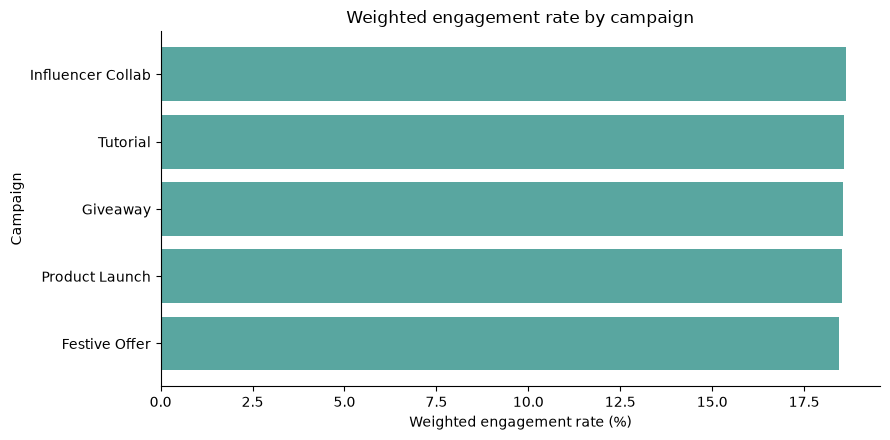

In [23]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_data = campaign_summary.sort_values("weighted_rate")
ax.barh(plot_data["campaign_type"].astype(str), plot_data["weighted_rate"] * 100, color="#59a6a0")
ax.set(title="Weighted engagement rate by campaign", xlabel="Weighted engagement rate (%)", ylabel="Campaign")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


### Engagement-source summary

Review descriptive performance associated with each engagement-source label.


In [24]:
source_summary = grouped_metrics(clean, "engagement_source").sort_values("weighted_rate", ascending=False)
display(source_summary.rename(columns={"engagement_source": "Engagement source", "records": "Records", "reach": "Summed reach", "engagements": "Engagements", "mean_post_rate": "Mean post rate", "weighted_rate": "Weighted rate", "record_share_pct": "Record share (%)"}))


,Engagement source,Records,Summed reach,Engagements,Mean post rate,Weighted rate,Record share (%)
1,Influencer,12501,246260595,45938061,0.185823,0.186542,25.002
0,Collab,12633,248952629,46382206,0.185880,0.186309,25.266
3,Paid,12358,242421718,44960053,0.185269,0.185462,24.716
2,Organic,12508,249788346,45884097,0.184429,0.183692,25.016


### Audience-emotion summary

Review descriptive performance by audience-emotion label; interpretation depends on how labels were assigned.


In [25]:
emotion_summary = grouped_metrics(clean, "audience_emotion").sort_values("weighted_rate", ascending=False)
display(emotion_summary.rename(columns={"audience_emotion": "Audience emotion", "records": "Records", "reach": "Summed reach", "engagements": "Engagements", "mean_post_rate": "Mean post rate", "weighted_rate": "Weighted rate", "record_share_pct": "Record share (%)"}))


,Audience emotion,Records,Summed reach,Engagements,Mean post rate,Weighted rate,Record share (%)
1,Curious,10027,196492666,36660489,0.186234,0.186574,20.054
3,Happy,9884,194124861,35964225,0.185045,0.185263,19.768
0,Confident,9891,194981141,36118278,0.185720,0.185240,19.782
4,Inspired,10137,201696366,37356748,0.185094,0.185213,20.274
2,Excited,10061,200128254,37064677,0.184671,0.185205,20.122


## 7. Time-Series Exploration

Aggregate records by month and compare volume and weighted engagement rate over time. A weekday comparison is also included where dates are available.

**Interpretation note:** changes can reflect seasonality, campaign mix, missing data, or measurement changes—not necessarily content quality. The source has dates but no publication time, so posting-hour conclusions are out of scope.


### Aggregate monthly performance

Aggregate dated records by calendar month and calculate volume, reach, engagements, and weighted rate.


In [26]:
valid_dates = clean.dropna(subset=["post_date"]).copy()
monthly = valid_dates.set_index("post_date").resample("MS").agg(
    records=("reach", "size"), reach=("reach", "sum"), engagements=("total_engagements", "sum"),
).reset_index()
monthly["weighted_rate"] = monthly["engagements"] / monthly["reach"].where(monthly["reach"] > 0)
monthly["month"] = monthly["post_date"].dt.strftime("%b %Y")


### Monthly summary table

Check coverage and denominators alongside each monthly rate.


In [27]:
display(monthly[["month", "records", "reach", "engagements", "weighted_rate"]].rename(columns={"month": "Month", "records": "Records", "reach": "Summed reach", "engagements": "Engagements", "weighted_rate": "Weighted rate"}))

,Month,Records,Summed reach,Engagements,Weighted rate
0,Apr 2024,1626,32420356,5911391,0.182336
1,May 2024,4250,83453920,15476837,0.185454
2,Jun 2024,4232,84035874,15639976,0.186111
3,Jul 2024,4121,80383561,14873164,0.185027
4,Aug 2024,4242,84298737,15530135,0.184227
5,Sep 2024,4160,81579614,15237467,0.186780
6,Oct 2024,4225,83992149,15489560,0.184417
7,Nov 2024,4075,80335997,14920330,0.185724
8,Dec 2024,4296,84135676,15590616,0.185303
9,Jan 2025,4244,83461303,15647029,0.187476


### Plot monthly record volume

Volume changes help contextualize changes in performance rates.


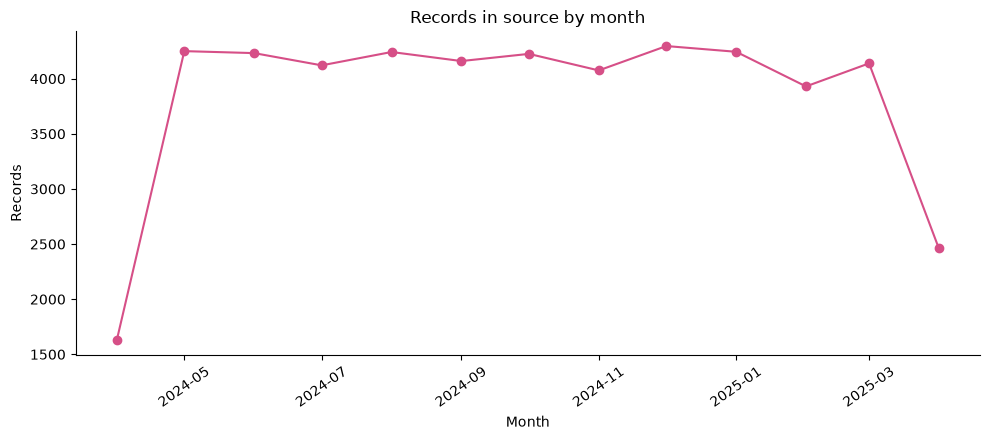

In [28]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly["post_date"], monthly["records"], marker="o", color="#d64f87")
ax.set(title="Records in source by month", xlabel="Month", ylabel="Records")
ax.tick_params(axis="x", rotation=35)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


### Plot monthly weighted engagement rate

Patterns may be worth investigating while accounting for campaign mix and incomplete periods.


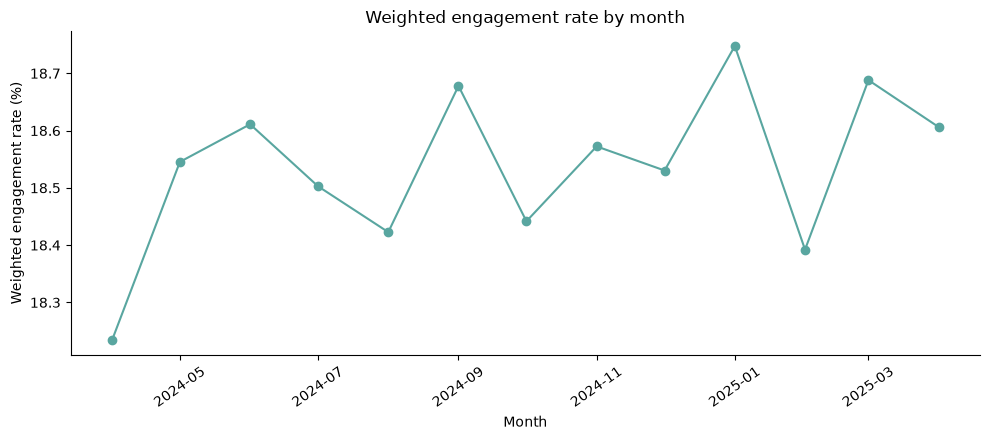

In [29]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly["post_date"], monthly["weighted_rate"] * 100, marker="o", color="#59a6a0")
ax.set(title="Weighted engagement rate by month", xlabel="Month", ylabel="Weighted engagement rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


### Compare weekdays

Derive weekday labels from valid dates and summarize weighted rate by weekday.


In [30]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = grouped_metrics(valid_dates, "weekday")
weekday_summary["weekday"] = pd.Categorical(weekday_summary["weekday"], categories=weekday_order, ordered=True)
weekday_summary = weekday_summary.sort_values("weekday")
display(weekday_summary.rename(columns={"weekday": "Weekday", "records": "Records", "reach": "Summed reach", "engagements": "Engagements", "mean_post_rate": "Mean post rate", "weighted_rate": "Weighted rate", "record_share_pct": "Record share (%)"}))


,Weekday,Records,Summed reach,Engagements,Mean post rate,Weighted rate,Record share (%)
1,Monday,7094,140535656,26031326,0.184815,0.185229,14.188
5,Tuesday,7355,145331388,26972261,0.185744,0.185591,14.710
6,Wednesday,7179,142650866,26469870,0.186292,0.185557,14.358
4,Thursday,7068,140030360,25956946,0.184766,0.185367,14.136
0,Friday,7245,143101982,26629803,0.185680,0.186090,14.490
2,Saturday,7031,137103998,25492755,0.185952,0.185937,14.062
3,Sunday,7028,138669038,25611456,0.184174,0.184695,14.056


### Visualize weekday engagement rates

Compare weekdays descriptively; do not infer an optimal schedule from this chart alone.


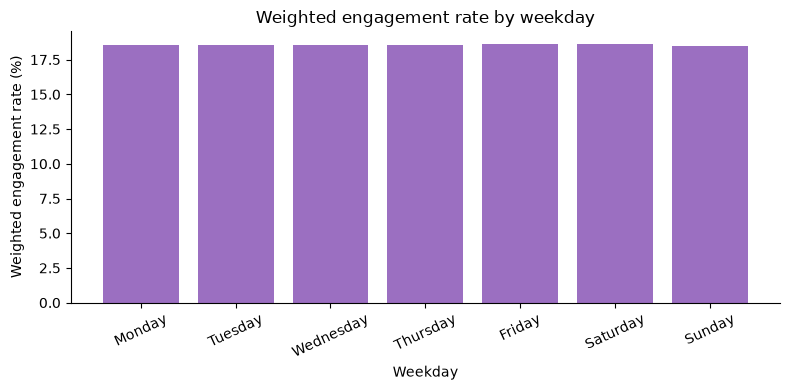

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(weekday_summary["weekday"].astype(str), weekday_summary["weighted_rate"] * 100, color="#9b6fc1")
ax.set(title="Weighted engagement rate by weekday", xlabel="Weekday", ylabel="Weighted engagement rate (%)")
ax.tick_params(axis="x", rotation=25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


## 8. Hashtag Exploration

Extract hashtags from the supplied text and summarize their frequency and associated descriptive metrics.

**Important:** one record can contain multiple hashtags, so groups overlap. Do not sum reach or engagement across tags as if each tag represented a separate audience. Associations do not prove that adding a hashtag will improve performance.


### Parse and aggregate hashtags

Each post contributes at most once to a given hashtag, even if the same tag appears repeatedly.


In [32]:
hashtag_rows = []
for row in clean[["hashtags", "reach", "total_engagements"]].itertuples(index=False):
    tags = set(tag.lower() for tag in re.findall(r"#\w+", str(row.hashtags)))
    for tag in tags:
        hashtag_rows.append({"hashtag": tag, "reach": row.reach, "engagements": row.total_engagements})

if hashtag_rows:
    hashtag_records = pd.DataFrame(hashtag_rows)
    hashtag_summary = hashtag_records.groupby("hashtag").agg(
        records=("hashtag", "size"), reach=("reach", "sum"), engagements=("engagements", "sum")
    ).reset_index()
    hashtag_summary["weighted_rate"] = hashtag_summary["engagements"] / hashtag_summary["reach"].where(hashtag_summary["reach"] > 0)
    hashtag_summary["usage_share_pct"] = hashtag_summary["records"] / len(clean) * 100
else:
    hashtag_summary = pd.DataFrame(columns=["hashtag", "records", "reach", "engagements", "weighted_rate", "usage_share_pct"])


### Review hashtag metrics

The table reports frequent tags and associated metrics; hashtag audiences overlap.


In [33]:
top_hashtags = hashtag_summary.sort_values(["records", "hashtag"], ascending=[False, True]).head(20)
display(top_hashtags.rename(columns={"hashtag": "Hashtag", "records": "Records using tag", "reach": "Summed reach (overlapping)", "engagements": "Engagements (overlapping)", "weighted_rate": "Weighted rate", "usage_share_pct": "Records using tag (%)"}))


,Hashtag,Records using tag,Summed reach (overlapping),Engagements (overlapping),Weighted rate,Records using tag (%)
1,#crueltyfree,20197,401023498,74367686,0.185445,40.394
2,#makeupgoals,20018,396557791,73561353,0.185500,40.036
4,#veganbeauty,19982,395276422,73748880,0.186575,39.964
0,#boldlooks,19956,396241790,73651357,0.185875,39.912
3,#sugarcosmetics,19891,392559171,72678345,0.185140,39.782


### Plot the most frequent hashtags

Frequency is shown rather than causal impact. A common tag is not necessarily an effective tag.


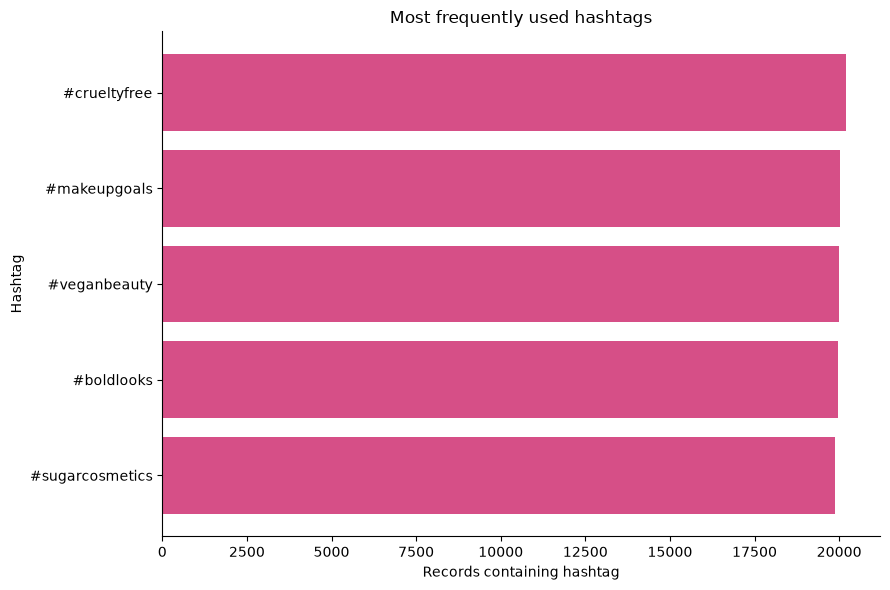

In [34]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_data = top_hashtags.sort_values("records")
ax.barh(plot_data["hashtag"], plot_data["records"], color="#d64f87")
ax.set(title="Most frequently used hashtags", xlabel="Records containing hashtag", ylabel="Hashtag")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()


## 9. Findings, Limitations, and Audit Exports

This section consolidates the descriptive results and documents the checks required before the analysis is used for business decisions. Findings should be reported with their supporting sample sizes, denominators, and data-quality context.

### Recommended Stakeholder Review

1. Confirm the source file, reporting period, row-level grain, and metric definitions with the data owner.
2. Investigate high-priority data-quality checks and reconcile unusual records against the source.
3. Compare category-level rates alongside record counts and denominators.
4. Treat time-series and hashtag patterns as hypotheses for follow-up testing rather than causal evidence.
5. Archive the cleaned dataset and audit outputs with the notebook version used to produce them.


### Summary of Key Descriptive Findings

The table below reports observed leaders calculated from the category and time-series summaries. These rankings are descriptive only. Before communicating a result, verify the associated sample size, denominator, data-quality flags, and consistency across reporting periods.


In [35]:
findings = pd.DataFrame([
    {"Finding": "Highest format weighted rate", "Observed": post_type_summary.iloc[0]["post_type"], "Interpretation": "Descriptive ranking; assess uncertainty before acting."},
    {"Finding": "Highest campaign weighted rate", "Observed": campaign_summary.iloc[0]["campaign_type"], "Interpretation": "Descriptive ranking; not a causal campaign effect."},
    {"Finding": "Most-recorded month", "Observed": monthly.loc[monthly["records"].idxmax(), "month"], "Interpretation": "Record volume is not confirmed publishing frequency."},
    {"Finding": "Most-used hashtag", "Observed": top_hashtags.iloc[0]["hashtag"] if len(top_hashtags) else "No tags parsed", "Interpretation": "Hashtag groups overlap; usage is not incremental reach."},
])
display(findings)


,Finding,Observed,Interpretation
0,Highest format weighted rate,Story,Descriptive ranking; assess uncertainty before...
1,Highest campaign weighted rate,Influencer Collab,Descriptive ranking; not a causal campaign eff...
2,Most-recorded month,Dec 2024,Record volume is not confirmed publishing freq...
3,Most-used hashtag,#crueltyfree,Hashtag groups overlap; usage is not increment...


### Limitations and Decision Considerations

- Provenance and one-row-per-post grain have not been independently verified.

- Dates have no publication time; no posting-hour conclusion is possible.

- There are no audience demographics, stable post IDs, captions, spend, revenue, or person-level conversion links.

- Category and hashtag summaries are observational and may be confounded by content, timing, or selection.

- Aggregate visit and follow ratios are proxies only. Financial impact requires attributed business outcomes.

- IQR outlier flags indicate unusual values, not confirmed errors. No outliers were removed.

### Reproduce and export

The cell below writes the non-destructive cleaned analysis data and quality summaries to the project paths used by the dashboard. Run it only after reviewing the checks above.


### Export the Analysis Dataset and Audit Artifacts

The next cell exports the standardized analysis dataset and machine-readable quality summaries to project-relative paths. Review the validation results before distributing these files, and retain the source fingerprint for traceability.


In [36]:
summary = {
    "source_file": source_path.relative_to(PROJECT_ROOT).as_posix(),
    "source_sha256": source_sha256,
    "rows": int(len(clean)),
    "source_columns": int(len(raw.columns)),
    "date_min": str(clean["post_date"].min()),
    "date_max": str(clean["post_date"].max()),
    "missing_cells_after_standardization": int(clean.isna().sum().sum()),
    "exact_duplicate_rows": int(clean.duplicated().sum()),
    "invalid_dates": int(clean["post_date"].isna().sum()),
    "provenance": "Source identity and collection method are unverified.",
    "cleaning_policy": "Standardize names and types; no rows dropped or imputed.",
    "notes": [
        "No stable post ID or exact publication time is present.",
        "Summed post-level reach is not unique account reach.",
        "Aggregate visit/follow rates are proxies, not attributed conversion.",
        "Category and hashtag comparisons are descriptive, not causal.",
        "Outliers are flagged for review and retained.",
    ],
}
quality_report = {
    "dataset_summary": summary,
    "quality_checks": quality_df.rename(columns={"Check": "check", "Count": "count", "Review priority": "severity", "Interpretation": "detail"}).to_dict(orient="records"),
    "outlier_summary": outlier_summary.rename(columns={"Metric": "metric", "Q1": "q1", "Q3": "q3", "IQR lower fence": "lower_iqr_fence", "IQR upper fence": "upper_iqr_fence", "Flagged rows": "flagged_count", "Flagged (%)": "flagged_pct"}).to_dict(orient="records"),
    "schema": schema.rename(columns={"Column": "column", "Type after parsing": "dtype", "Missing": "missing_count", "Missing (%)": "missing_pct", "Distinct non-missing": "unique_values"}).to_dict(orient="records"),
}

clean_path = DATA_DIR / "sugar_cosmetics_instagram_cleaned.csv"
clean.to_csv(clean_path, index=False)
(REPORT_DIR / "data_quality_report.json").write_text(json.dumps(quality_report, indent=2, default=str), encoding="utf-8")
quality_df.rename(columns={"Check": "check", "Count": "count", "Review priority": "severity", "Interpretation": "detail"}).to_csv(REPORT_DIR / "data_quality_checks.csv", index=False)
quality_report["outlier_summary"] and pd.DataFrame(quality_report["outlier_summary"]).to_csv(REPORT_DIR / "outlier_screening.csv", index=False)
print(f"Cleaned analysis data: {clean_path.relative_to(PROJECT_ROOT)}")
print("Quality report and check tables written to reports/.")


Cleaned analysis data: data\sugar_cosmetics_instagram_cleaned.csv
Quality report and check tables written to reports/.


## 10. Conclusion and Recommendations

### Executive Conclusion

This analysis establishes a reproducible baseline for assessing the supplied Instagram performance data and exploring descriptive differences across content formats, campaign types, time periods, and hashtags. Use the calculated outputs to identify areas for further investigation; do not treat a category ranking as proof of incremental business impact.

> **Decision rule:** Validate the source and metric definitions first. Treat observed leaders as candidates for controlled testing, and change publishing or campaign strategy only when results are repeatable and connected to a clearly defined business outcome.

### Key Results

The following output summarizes the overall KPIs and the strongest observed category-level results. Interpret each metric alongside its denominator, record count, and the data-quality findings documented earlier in the notebook.


In [ ]:
# Stakeholder-ready conclusion metrics (calculated from the analysis tables)
conclusion_metrics = overall_kpis.copy()
display(conclusion_metrics)

def _top_category_summary(summary_df, category_col):
    if summary_df.empty or "weighted_rate" not in summary_df.columns:
        return None
    eligible = summary_df.dropna(subset=["weighted_rate"]).sort_values("weighted_rate", ascending=False)
    return eligible.iloc[0] if not eligible.empty else None

top_format = _top_category_summary(post_type_summary, "post_type")
top_campaign = _top_category_summary(campaign_summary, "campaign_type")
recommendation_rows = []
if top_format is not None:
    recommendation_rows.append({
        "Priority": "Content format",
        "Observation": f"{top_format['post_type']} has the highest observed weighted engagement rate ({top_format['weighted_rate']:.2%}) across {int(top_format['records'])} records.",
        "Recommended action": "Validate with a balanced test and compare results over multiple posts before reallocating the content mix."
    })
if top_campaign is not None:
    recommendation_rows.append({
        "Priority": "Campaign",
        "Observation": f"{top_campaign['campaign_type']} has the highest observed weighted engagement rate ({top_campaign['weighted_rate']:.2%}) across {int(top_campaign['records'])} records.",
        "Recommended action": "Review campaign objectives, audience, creative and timing; repeat with comparable conditions to assess consistency."
    })
recommendation_rows.extend([
    {"Priority": "Data quality", "Observation": f"{int(df.isna().sum().sum())} missing cells remain in the standardized dataset and {int(df.duplicated().sum())} exact duplicate rows were detected.", "Recommended action": "Confirm source definitions and row grain with the data owner; investigate high-priority quality checks before operational decisions."},
    {"Priority": "Measurement", "Observation": "Reach is summed at record level and conversion metrics are aggregate proxies.", "Recommended action": "Capture stable post IDs, publication timestamps, campaign spend and attributed conversion outcomes for stronger comparisons."},
    {"Priority": "Experimentation", "Observation": "Category, weekday and hashtag comparisons are observational and may be confounded.", "Recommended action": "Predefine a success metric and run controlled tests with adequate sample sizes; track engagement and business outcomes together."},
])
recommendations = pd.DataFrame(recommendation_rows)
display(recommendations)


### Risks and Limitations

- **Unverified provenance:** the collection method, source ownership, and assumption that each row represents one unique post have not been independently confirmed.
- **Reach overlap:** summed post-level reach is not deduplicated account-level reach.
- **Limited attribution:** the dataset does not include spend, revenue, or person-level conversion links; aggregate visit and follow ratios are proxies only.
- **Potential confounding:** differences by post type, campaign, weekday, or hashtag may reflect audience, creative, timing, or sample-size differences.
- **Incomplete timing detail:** publication timestamps are unavailable, so the analysis cannot support posting-hour recommendations.
- **Outlier interpretation:** IQR flags identify unusual values, not confirmed errors. Flagged observations are retained for review.

### Recommended Next Steps

1. **Validate the source:** confirm the collection method, reporting period, metric definitions, and row-level grain with the data owner.
2. **Resolve priority data-quality issues:** inspect high-priority checks and reconcile suspicious records against source records.
3. **Run controlled tests:** compare content formats and campaigns under comparable conditions, with predefined success metrics and adequate sample sizes.
4. **Improve measurement:** capture stable post IDs, exact publication timestamps, campaign spend, and attributable conversion outcomes.
5. **Operationalize reporting:** refresh the notebook on a consistent schedule and compare periods only when coverage and definitions are comparable.

### Final Decision Statement

Use this notebook as a baseline for performance monitoring and hypothesis generation. Before reallocating resources or changing the content strategy, validate the data and confirm that observed differences persist in repeatable tests tied to business outcomes.
